In [4]:
cd ..

c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines


In [6]:
!dir

 Volume in drive C is Windows
 Volume Serial Number is FE83-5B3B

 Directory of c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines

17/12/2025  10:56    <DIR>          .
16/12/2025  16:35    <DIR>          ..
16/12/2025  16:35                54 .gitignore
16/12/2025  16:55               437 .gitmodules
16/12/2025  17:25    <DIR>          .vscode
16/12/2025  16:54    <DIR>          base
17/12/2025  11:50    <DIR>          build
16/12/2025  16:39    <DIR>          data
16/12/2025  16:35            15'429 environment.yml
16/12/2025  17:16    <DIR>          notebooks
16/12/2025  16:35               236 README.md
17/12/2025  11:39    <DIR>          temp
               4 File(s)         16'156 bytes
               8 Dir(s)  340'112'310'272 bytes free


In [11]:
import numpy as np
import matplotlib.pyplot as plt

from base.utils import array_to_o3d
from pc_skeletor import LBC
from stl import mesh

In [13]:
meshdata = mesh.Mesh.from_file("./temp/real/Meandre.stl")

In [14]:
pcd = meshdata.centroids
    
## local shift
local_shift = np.mean(pcd, axis = 0)

# convert to open3d object-
shifted_pcd = array_to_o3d(pcd - local_shift)

In [15]:
shifted_pcd

PointCloud with 570910 points.

In [16]:
skeleton_clouds = []

skeleton_clouds.append(shifted_pcd)

for max_it_step in range(1,6):
    # set up the Laplacian-based contraction algorithm 
    lbc = LBC(point_cloud=shifted_pcd, 
              down_sample=0.2,
              init_attraction = 2, 
              init_contraction = 0.5, 
              max_iteration_steps=max_it_step)
    lbc.extract_skeleton()
    skeleton_clouds.append(lbc.contracted_point_cloud)

2025-12-17 11:52:26,805 - PCD #points: 15924
Volume ratio: 1.0. Contraction weights: 84.35370778374137. Attraction weights: 2.0. Progress LBC: 100%|██████████| 1/1 [00:01<00:00,  1.46s/it]2025-12-17 11:52:29,814 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 84.35370778374137. Attraction weights: 2.0. Progress LBC: 100%|██████████| 1/1 [00:02<00:00,  2.23s/it]
2025-12-17 11:52:29,919 - PCD #points: 15924


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 421.768538918707. Attraction weights: 2.0. Progress LBC: 100%|██████████| 2/2 [00:03<00:00,  1.73s/it] 2025-12-17 11:52:34,748 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 421.768538918707. Attraction weights: 2.0. Progress LBC: 100%|██████████| 2/2 [00:04<00:00,  2.07s/it]
2025-12-17 11:52:34,846 - PCD #points: 15924


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 2048.0. Attraction weights: 3.0869016589069442. Progress LBC: 100%|██████████| 3/3 [00:04<00:00,  1.55s/it]2025-12-17 11:52:41,205 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 2048.0. Attraction weights: 3.0869016589069442. Progress LBC: 100%|██████████| 3/3 [00:05<00:00,  1.88s/it]
2025-12-17 11:52:41,306 - PCD #points: 15924


Contraction is Done.


Volume ratio: 0.5863554108933073. Contraction weights: 2048.0. Attraction weights: 29.379610656359095. Progress LBC: 100%|██████████| 4/4 [00:06<00:00,  1.51s/it]2025-12-17 11:52:50,550 - Contraction is Done.
Volume ratio: 0.5863554108933073. Contraction weights: 2048.0. Attraction weights: 29.379610656359095. Progress LBC: 100%|██████████| 4/4 [00:08<00:00,  2.06s/it]
2025-12-17 11:52:50,656 - PCD #points: 15924


Contraction is Done.


Volume ratio: 0.5863554108933073. Contraction weights: 2048.0. Attraction weights: 29.379610656359095. Progress LBC:  80%|████████  | 4/5 [00:06<00:01,  1.43s/it]2025-12-17 11:52:59,398 - Contraction is Done.
Volume ratio: 0.5863554108933073. Contraction weights: 2048.0. Attraction weights: 29.379610656359095. Progress LBC:  80%|████████  | 4/5 [00:07<00:01,  1.99s/it]

Contraction is Done.


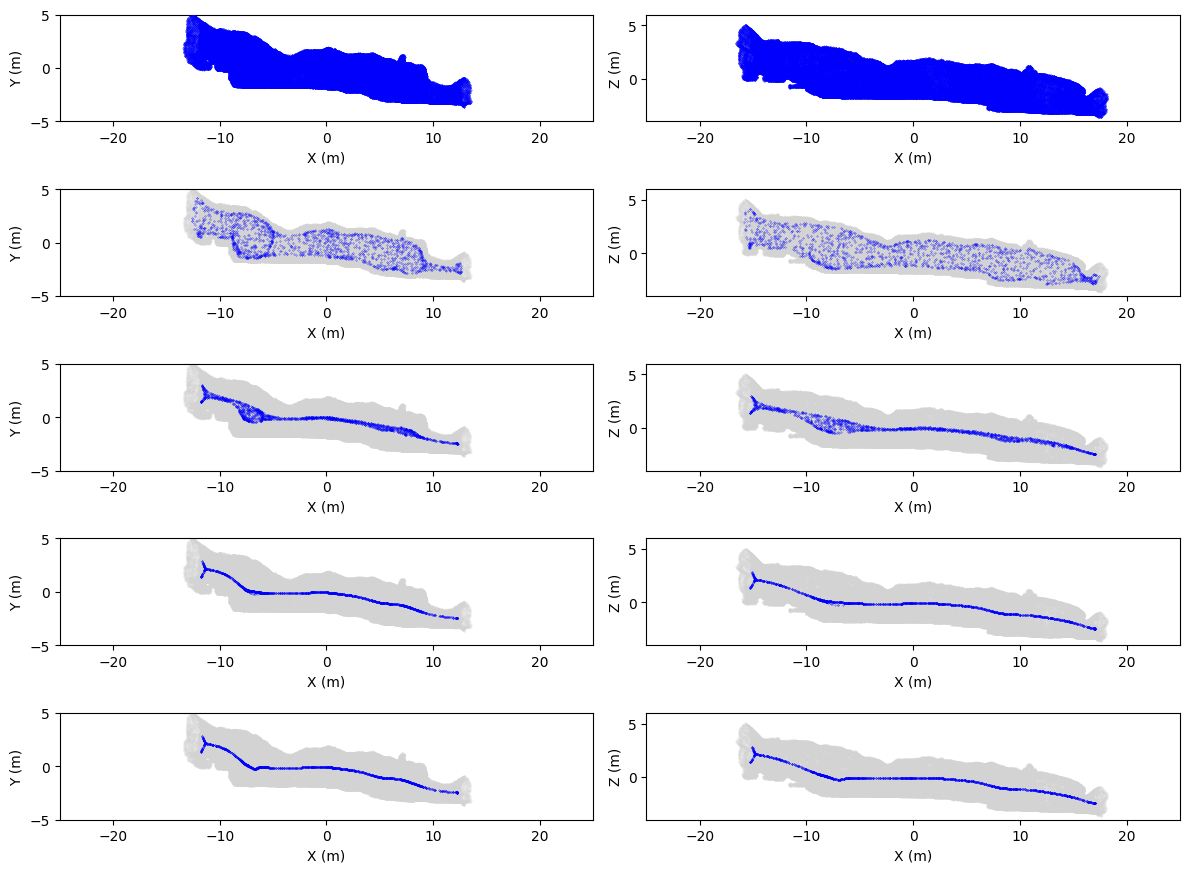

In [19]:
fig, axes = plt.subplots(5,2, figsize =(12, 9))

for i in range(0,5):
    axes[i, 0].scatter(*np.asarray(skeleton_clouds[i].points)[::10, [1,2]].T, color = "blue", s=0.05, zorder = 100)
    axes[i, 0].scatter(*np.asarray(skeleton_clouds[0].points)[::10, [1,2]].T, color = "lightgrey", s=0.05, zorder = -100, alpha = 0.5)

    axes[i, 0].set_aspect("equal")
    axes[i, 0].set_xlim(-25,25)
    axes[i, 0].set_ylim(-5,5)
    axes[i, 0].set_xlabel("X (m)")
    axes[i, 0].set_ylabel("Y (m)")

    axes[i, 1].scatter(*np.asarray(skeleton_clouds[i].points)[::10, [0,2]].T, color = "blue", s=0.05, zorder = 100)
    axes[i, 1].scatter(*np.asarray(skeleton_clouds[0].points)[::10, [0,2]].T, color = "lightgrey", s=0.05, zorder = -100, alpha = 0.5)

    axes[i, 1].set_aspect("equal")
    axes[i, 1].set_xlim(-25,25)
    axes[i, 1].set_ylim(-4,6)
    axes[i, 1].set_xlabel("X (m)")
    axes[i, 1].set_ylabel("Z (m)")




plt.tight_layout()

plt.savefig("./temp/outputs/iterative_contraction.png")

In [20]:
lbc.contracted_point_cloud

PointCloud with 15924 points.